# Лабораторная работа № 2 — задание 1

Выполняли Свешников Борис — ИСУ 467394 и Хасанов Дмитрий — ИСУ 467920.

## Условие и вычисление варианта

Номер варианта равен сумме ИСУ-идентификаторов по модулю 6 плюс 1:

$$467394+467920=935314,\qquad 935314\bmod 6+1=4+1=5.$$

**Вариант 5.** Методом моментов найти оценку параметра $\theta>0$ распределения с плотностью

$$p_\theta(t)=\theta t^{\theta-1}\mathbb{1}(t\in(0,1)).$$

Нужно найти смещение, дисперсию (или асимптотическую дисперсию), среднеквадратическую ошибку и обосновать свойства оценки. Затем для массива объёмов выборки требуется провести многократное моделирование, посчитать выборочные характеристики ошибки между оценкой и истинным параметром, число превышений заданного порога и визуализировать результаты.

In [1]:
import numpy as np
from IPython.display import Image, display

from plots.graphs import *
from utils.monte_carlo import run_monte_carlo

SEED = 24422442
RNG = np.random.default_rng(SEED)
THETA = 2.0
SMALL_N = np.linspace(10, 100, 19, dtype=int)
BIG_N = np.linspace(100, 10**4, 19, dtype=int)
VERY_BIG_N = np.linspace(10**5, 10**6, 11, dtype=int)
N = [SMALL_N, BIG_N, VERY_BIG_N]
M = 100
ERROR_THRESHOLD = 0.1
threshold = THETA * ERROR_THRESHOLD

isu = (467394, 467920)
variant = sum(isu) % 6 + 1

variant

5

### Параметры вычислительного эксперимента

Используем три шкалы объёмов выборки:

Для каждого $n$ генерируем $M=100$ независимых выборок. Для каждой выборки вычисляем оценку $\widehat\theta$ и разность $\widehat\theta-\theta.$

Существенной считаем относительную ошибку больше $10\%$:

$$\frac{|\widehat\theta-\theta|}{\theta}>0.1$$

При $\theta=2$ абсолютный порог равен $\varepsilon=0.2$, а допустимый интервал имеет вид $[1.8,2.2]$.

## Распределение

Сначала проверим, что заданная функция является плотностью. При $\theta>0$ она неотрицательна и

$$\int_{-\infty}^{\infty}p_\theta(t)\,dt
=\int_0^1\theta t^{\theta-1}\,dt
=\left[t^\theta\right]_0^1=1$$

Воспользуемся подсказкой и посмотрим на плотность бета-распределения:

$$p_{\alpha,\beta}(t)
=\frac{1}{B(\alpha,\beta)}t^{\alpha-1}(1-t)^{\beta-1}
\mathbb{1}(t\in(0,1))$$

При $\alpha=\theta$ и $\beta=1$

$$B(\theta,1)
=\frac{\Gamma(\theta)\Gamma(1)}{\Gamma(\theta+1)}
=\frac{\Gamma(\theta)}{\theta*\Gamma(\theta)}
=\frac1\theta$$

поэтому это и есть плотность нашего распределения в задаче. 

$$p_{\theta,1}(t)=\theta t^{\theta-1}\mathbb{1}(t\in(0,1))=p_\theta(t)$$

$$X\sim\operatorname{Beta}(\theta,1)$$

Выбрали $\theta = 2$, чтобы формула плотности была простой, но не тривиальной - $p_\theta(t) = 2t\mathbb{1}(t\in(0,1))$.

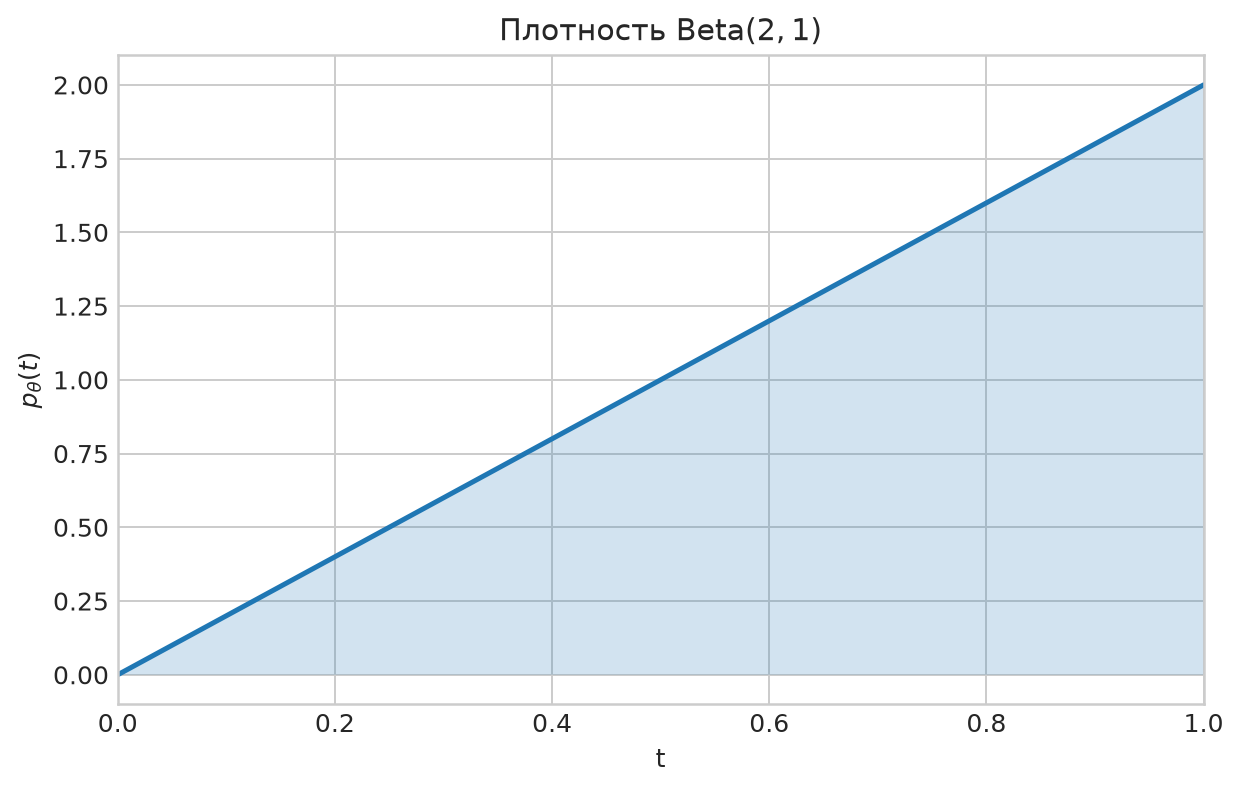

In [2]:
density_image = save_beta_density_plot(THETA)
display(Image(filename=str(density_image)))

In [3]:
experiments = []
for sizes in N:
    experiment = run_monte_carlo(
        THETA,
        sizes,
        M,
        RNG,
    )
    experiments.append(experiment)

## Оценка методом моментов

Сначала найдём теоретический первый момент одного наблюдения:

$$\mathbb E X
=\int_0^1t\,p_\theta(t)\,dt
=\int_0^1t\theta t^{\theta-1}\,dt
=\theta\int_0^1t^\theta\,dt
=\frac{\theta}{\theta+1}$$

В методе моментов приравниваем его к выборочному среднему:

$$\overline X=\frac{\widehat\theta}{\widehat\theta+1}$$

Решаем уравнение относительно $\widehat\theta$:

$$\overline X(\widehat\theta+1)=\widehat\theta$$

$$\overline X=\widehat\theta(1-\overline X)$$

$$\boxed{\widehat\theta=\frac{\overline X}{1-\overline X}}$$

Для каждой сгенерированной выборки сначала вычисляется $\overline X$, а после получается отдельная оценка $\widehat\theta$.

Отклонение среднего от истинного параметра:
n =      10: Δ = +0.261748
n =      15: Δ = +0.019393
n =      20: Δ = +0.095832
n =      25: Δ = +0.051464
n =      30: Δ = +0.090118
n =      35: Δ = -0.016476
n =      40: Δ = +0.027194
n =      45: Δ = +0.101917
n =      50: Δ = +0.068307
n =      55: Δ = -0.009004
n =      60: Δ = +0.012151
n =      65: Δ = +0.020917
n =      70: Δ = +0.035252
n =      75: Δ = +0.036426
n =      80: Δ = +0.023716
n =      85: Δ = +0.013435
n =      90: Δ = -0.015528
n =      95: Δ = +0.004434
n =     100: Δ = +0.020627


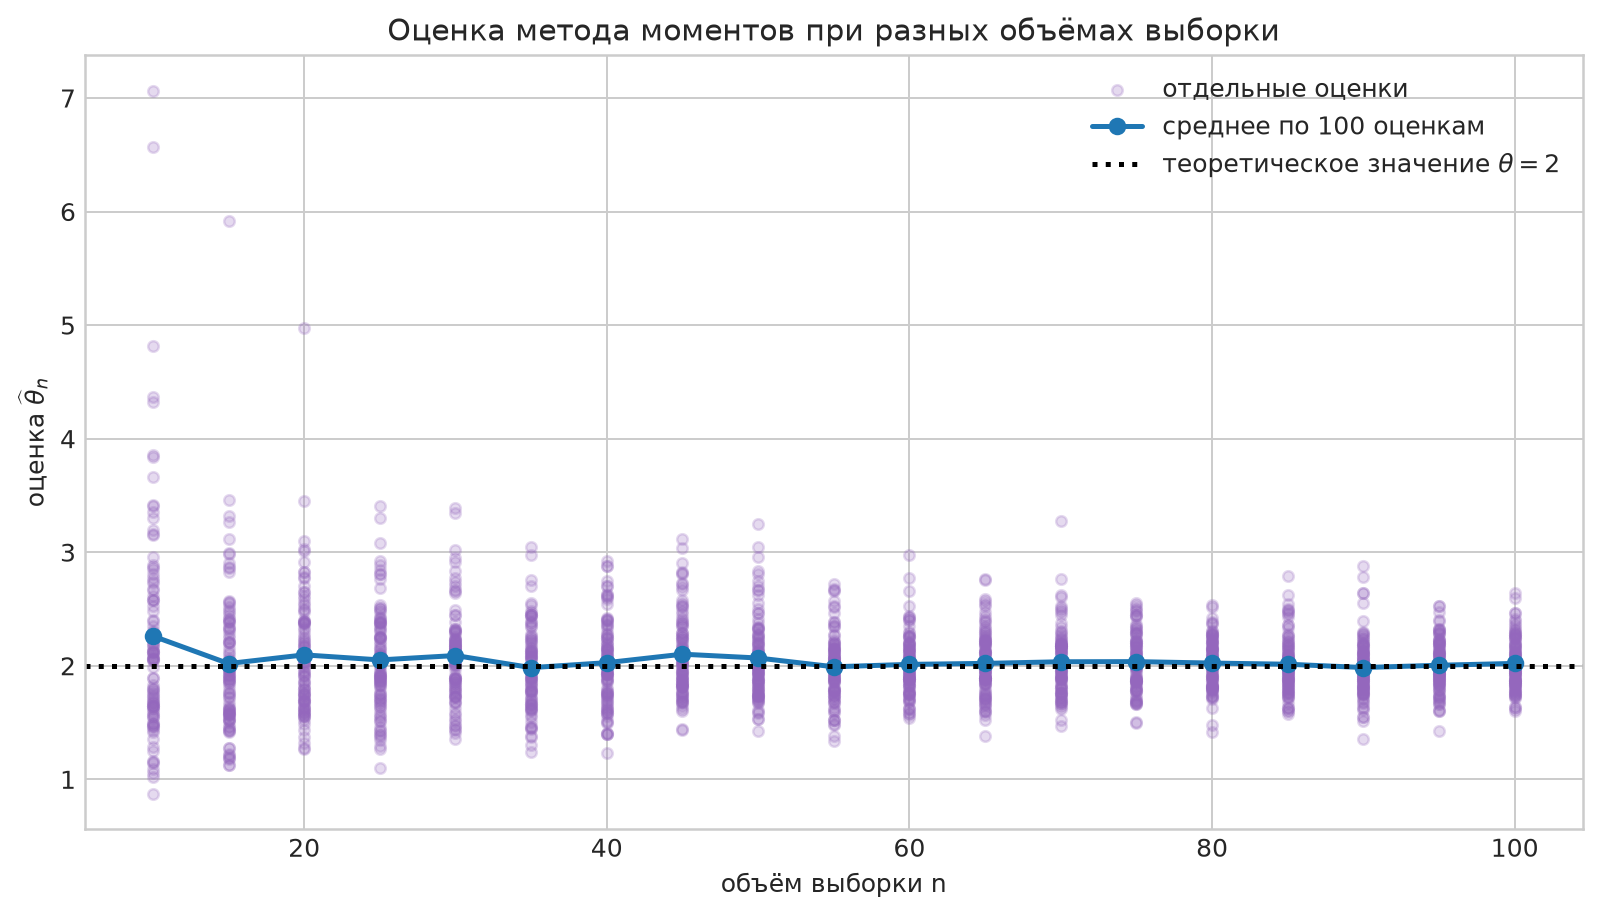

Отклонение среднего от истинного параметра:
n =     100: Δ = -0.005950
n =     650: Δ = -0.003475
n =    1200: Δ = -0.007132
n =    1750: Δ = -0.002734
n =    2300: Δ = -0.001589
n =    2850: Δ = -0.004932
n =    3400: Δ = +0.003473
n =    3950: Δ = -0.000523
n =    4500: Δ = -0.003855
n =    5050: Δ = -0.000143
n =    5600: Δ = +0.000496
n =    6150: Δ = -0.001605
n =    6700: Δ = +0.002230
n =    7250: Δ = -0.001772
n =    7800: Δ = -0.000135
n =    8350: Δ = -0.002906
n =    8900: Δ = +0.000404
n =    9450: Δ = -0.004472
n =   10000: Δ = -0.000693


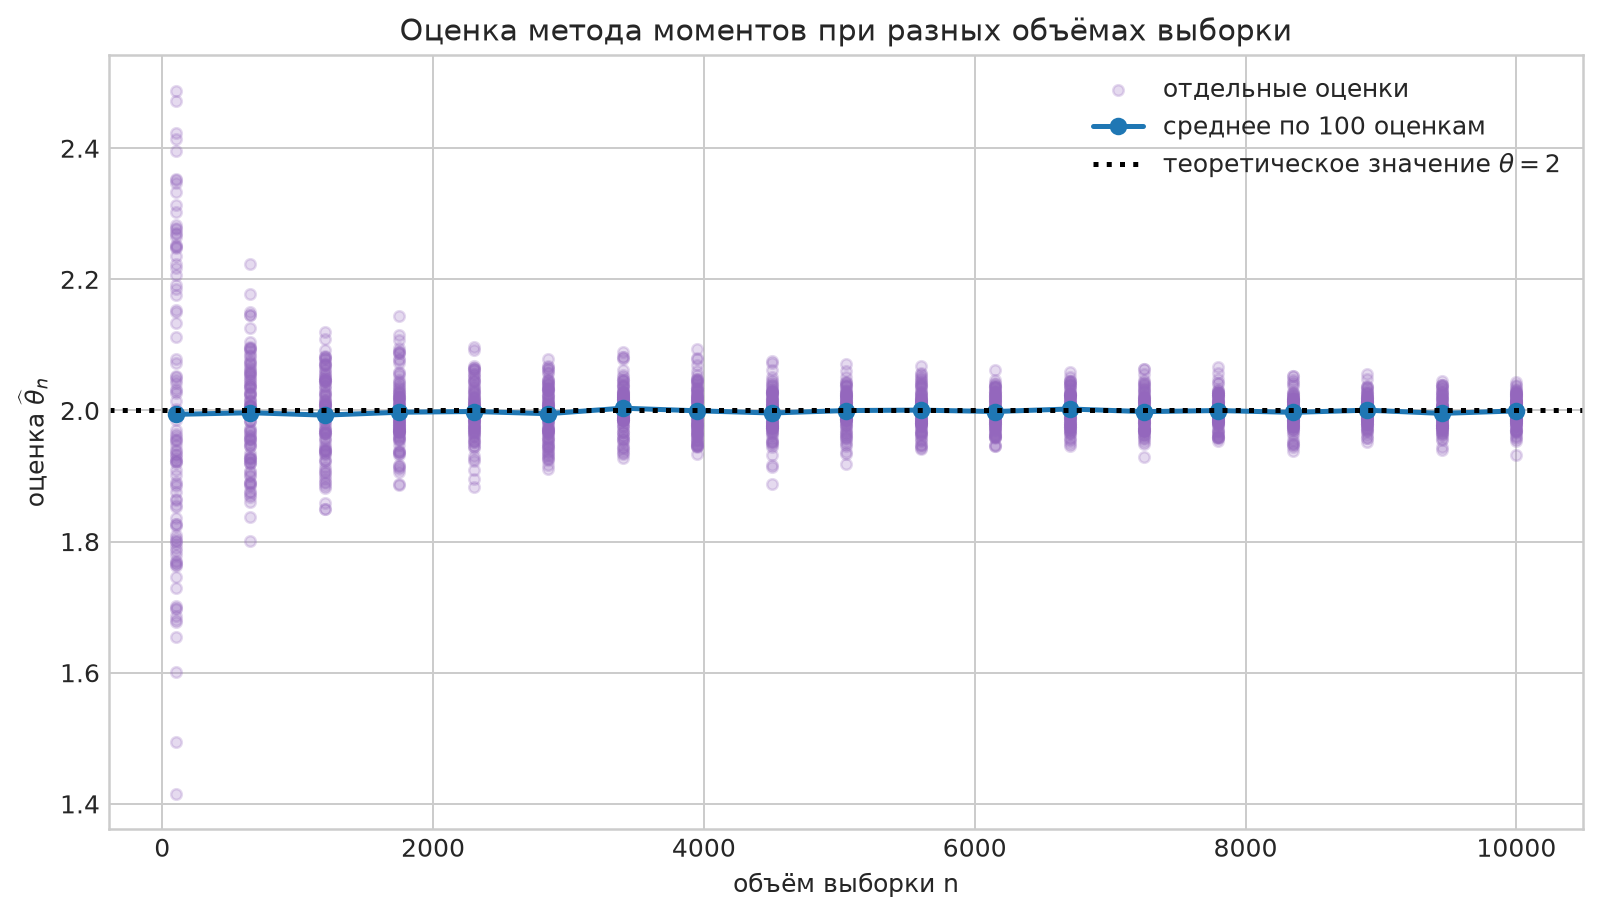

Отклонение среднего от истинного параметра:
n =  100000: Δ = +0.000066
n =  190000: Δ = -0.000810
n =  280000: Δ = +0.000104
n =  370000: Δ = +0.000367
n =  460000: Δ = -0.000106
n =  550000: Δ = +0.000357
n =  640000: Δ = +0.000072
n =  730000: Δ = -0.000232
n =  820000: Δ = +0.000218
n =  910000: Δ = +0.000068
n = 1000000: Δ = -0.000298


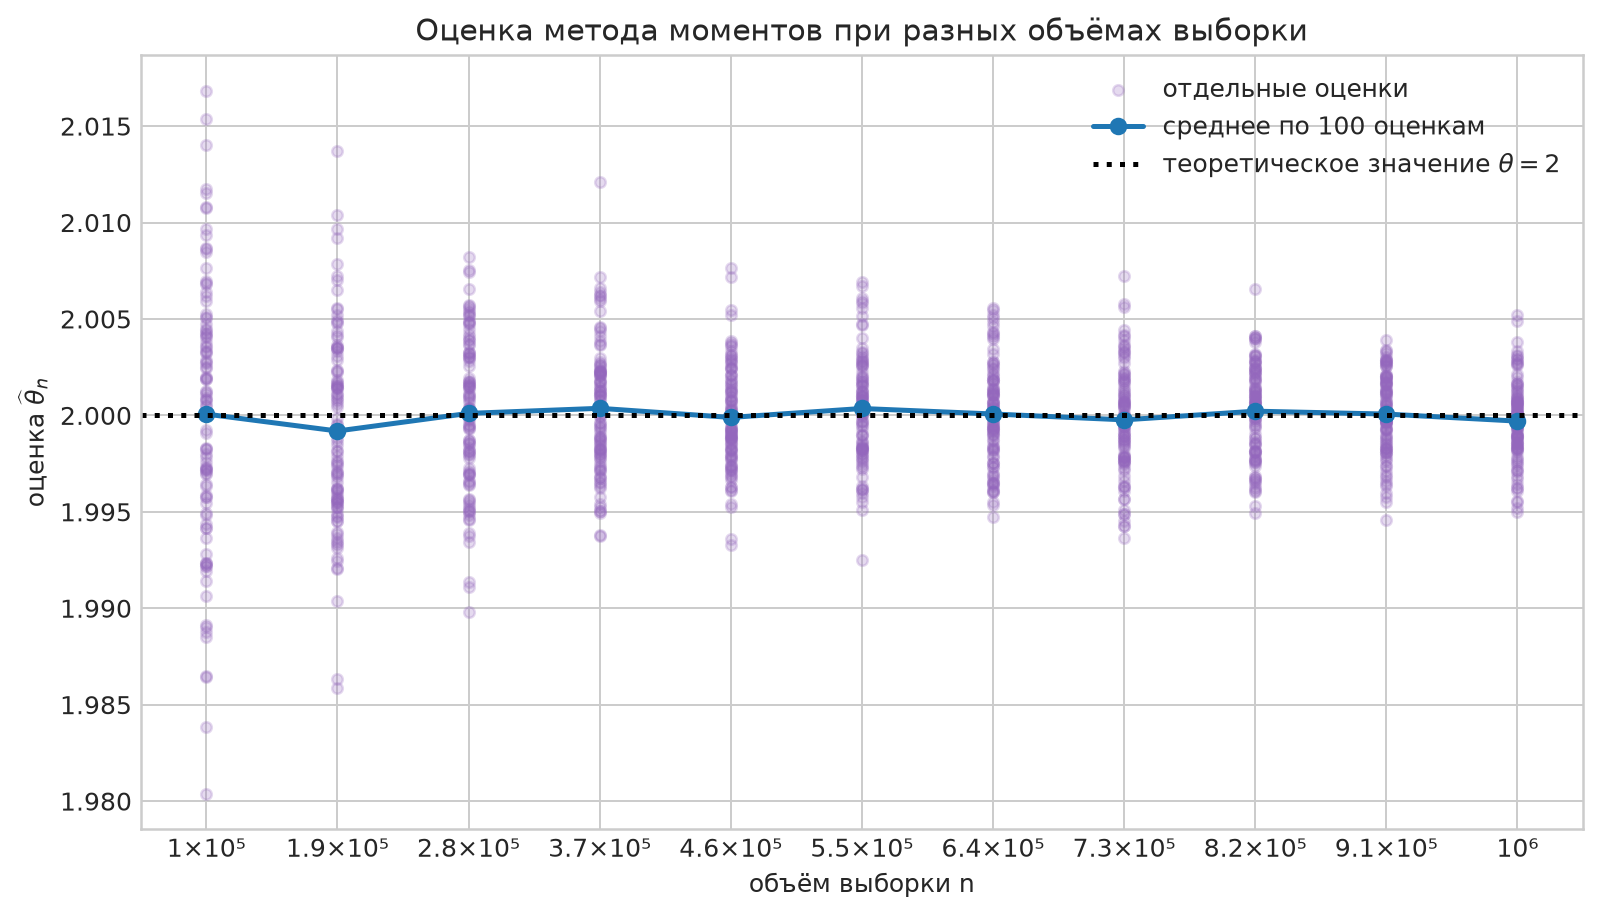

In [4]:
for sizes, experiment in zip(N, experiments):
    print(
        "Отклонение среднего от истинного параметра:"
    )
    for n in sizes:
        mean = experiment["results"][int(n)].mean()
        delta = mean - THETA
        
        print(f"n = {n:7d}: Δ = {delta:+.6f}")

    image = save_estimator_benchmark_plot(experiment, THETA)
    display(Image(filename=str(image)))

#### Вывод

С ростом $n$ отдельные оценки концентрируются около истинного значения $\theta=2$, а среднее всё ближе и ближе к прямой $y=2$. 

## Смещение

$$\widehat\theta=\frac{\overline X}{1-\overline X}.$$

$$\operatorname{Bias}(\widehat\theta)
=\mathbb E[\widehat\theta]-\theta.$$

В нашем эксперименте истинный параметр равен $\theta=2$. Поэтому для нахождения смещения достаточно вычислить $\mathbb E[\widehat\theta]$ и вычесть из него $2$.

### Асимптотическое математическое ожидание

В нашей задаче

$$X\sim\operatorname{Beta}(\theta,1)$$

Математическое ожидание и дисперсия равны:

$$\mathbb E X
=\frac{\theta}{\theta+1}
=\frac{2}{2+1}
=\frac23$$

$$\operatorname{Var}(X)
=\frac{\theta}{(\theta+1)^2(\theta+2)}
=\frac{2}{(2+1)^2(2+2)}
=\frac1{18}$$

Обозначим отклонение выборочного среднего от его математического ожидания через

$$T=\overline X-\mu=\overline X-\frac23$$
$$\mathbb E T=0,
\qquad
\mathbb E T^2=\operatorname{Var}(\overline X)
=\frac{\sigma^2}{n}=\frac1{18n}$$

По цпт

$$\sqrt n\left(\overline X-\mu\right)
=\sqrt n\,T
\xrightarrow{d}N\!\left(0,\sigma^2\right)
=N\!\left(0,\frac1{18}\right)$$

$$T
\xrightarrow{d}N\!(0,\frac{1}{18n})$$

Матожидание 0, поэтому $Var(T) = \mathbb E T^2 = \frac{1}{18n}$, по Чебышеву: 

$$
P\left(|T|>\frac M{\sqrt n}\right)
\leq
\frac{\operatorname{Var}(T)}{M^2/n}
=\frac{1}{18M^2}
$$

Для любого $\varepsilon$ достаточно взять $M$ настолько большим, чтобы
$$
\frac{1}{18M^2}<\varepsilon
$$

Значит, по определению:
$$
\boxed{T=O(n^{-1/2})}
$$
 
Иными словами, отклонение выборочного среднего от $2/3$ пропорционален $\frac{1}{\sqrt n}$. И $T\xrightarrow{p}0$, поэтому около точки $\mu=2/3$ можно использовать разложение Тейлора.

Оценка является функцией выборочного среднего:

$$\widehat\theta=g(\overline X)
\qquad
g(x)=\frac{x}{1-x}$$

$$f(x+t)
=f(x)+f'(x)t+\frac{f''(x)}2t^2+o(t^2)
\qquad t\to0$$

$$g'(x)=\frac1{(1-x)^2}
\qquad
g''(x)=\frac2{(1-x)^3}$$

поэтому

$$g\!\left(\frac23\right)=2
\qquad
g'\!\left(\frac23\right)=9
\qquad
g''\!\left(\frac23\right)=54$$

$$\widehat\theta
=g\!\left(\frac23+T\right)
=2+9T+27T^2+o(T^2)$$

$$T^2=O(n^{-1})$$

$$\widehat\theta
=2+9T+27T^2+o(n^{-1})$$

Берём математическое ожидание ($\mathbb E T=0$):

$$\mathbb E\widehat\theta
=2+27\mathbb E T^2+o(n^{-1})
=2+\frac{27}{18n}+o(n^{-1})$$

$$
\mathbb E\widehat\theta
=2+\frac{3}{2n}+o(n^{-1})$$

$$\boxed{
\operatorname{Bias}(\widehat\theta)
=\frac{3}{2n}+o(n^{-1})
}$$


Отклонение смещения в эксперименте от асимптотического:
n =      10: Δ = +0.111748
n =      15: Δ = -0.080607
n =      20: Δ = +0.020832
n =      25: Δ = -0.008536
n =      30: Δ = +0.040118
n =      35: Δ = -0.059333
n =      40: Δ = -0.010306
n =      45: Δ = +0.068583
n =      50: Δ = +0.038307
n =      55: Δ = -0.036277
n =      60: Δ = -0.012849
n =      65: Δ = -0.002160
n =      70: Δ = +0.013824
n =      75: Δ = +0.016426
n =      80: Δ = +0.004966
n =      85: Δ = -0.004212
n =      90: Δ = -0.032195
n =      95: Δ = -0.011355
n =     100: Δ = +0.005627


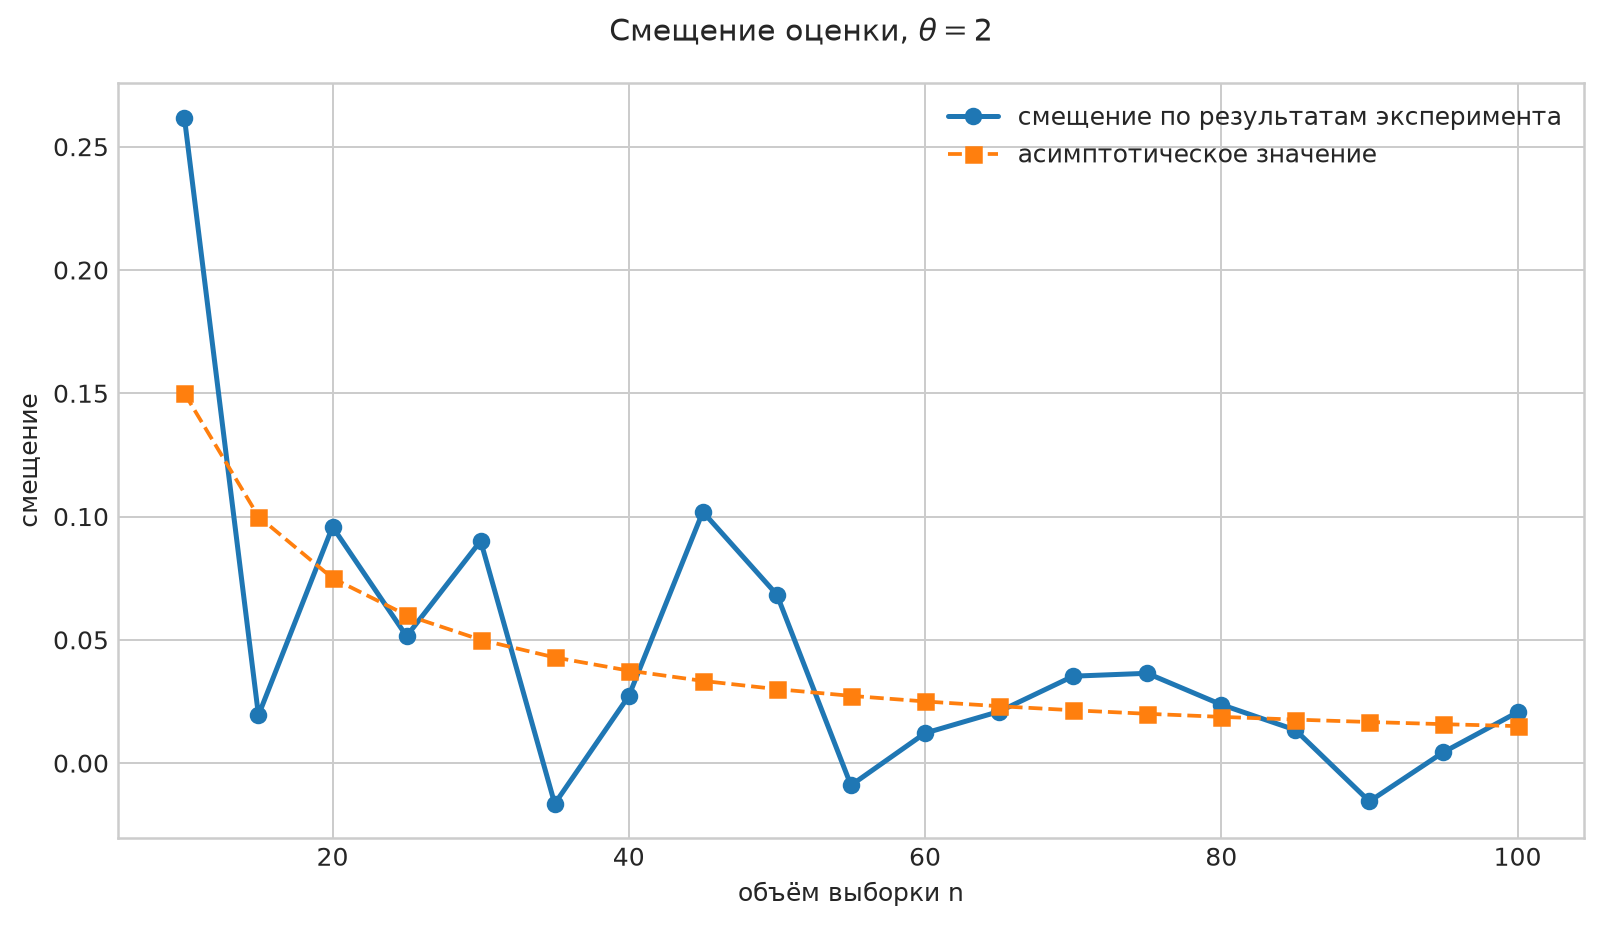

Отклонение смещения в эксперименте от асимптотического:
n =     100: Δ = -0.020950
n =     650: Δ = -0.005782
n =    1200: Δ = -0.008382
n =    1750: Δ = -0.003591
n =    2300: Δ = -0.002241
n =    2850: Δ = -0.005458
n =    3400: Δ = +0.003031
n =    3950: Δ = -0.000903
n =    4500: Δ = -0.004189
n =    5050: Δ = -0.000440
n =    5600: Δ = +0.000228
n =    6150: Δ = -0.001849
n =    6700: Δ = +0.002006
n =    7250: Δ = -0.001979
n =    7800: Δ = -0.000327
n =    8350: Δ = -0.003086
n =    8900: Δ = +0.000235
n =    9450: Δ = -0.004631
n =   10000: Δ = -0.000843


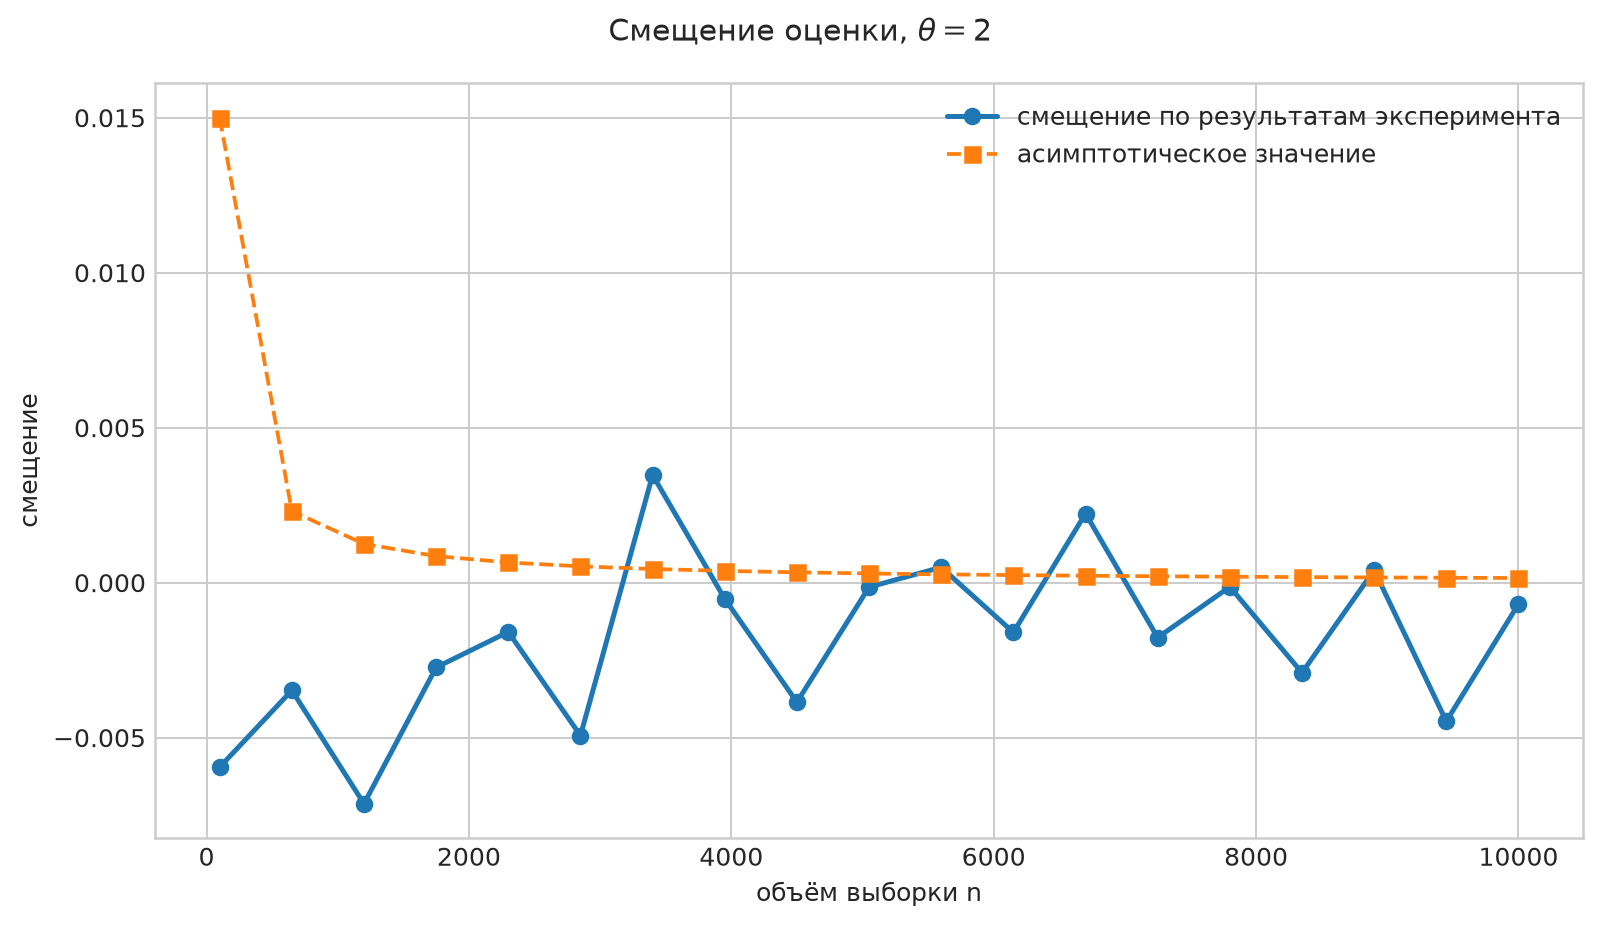

Отклонение смещения в эксперименте от асимптотического:
n =  100000: Δ = +0.000051
n =  190000: Δ = -0.000818
n =  280000: Δ = +0.000098
n =  370000: Δ = +0.000363
n =  460000: Δ = -0.000109
n =  550000: Δ = +0.000354
n =  640000: Δ = +0.000070
n =  730000: Δ = -0.000234
n =  820000: Δ = +0.000216
n =  910000: Δ = +0.000066
n = 1000000: Δ = -0.000300


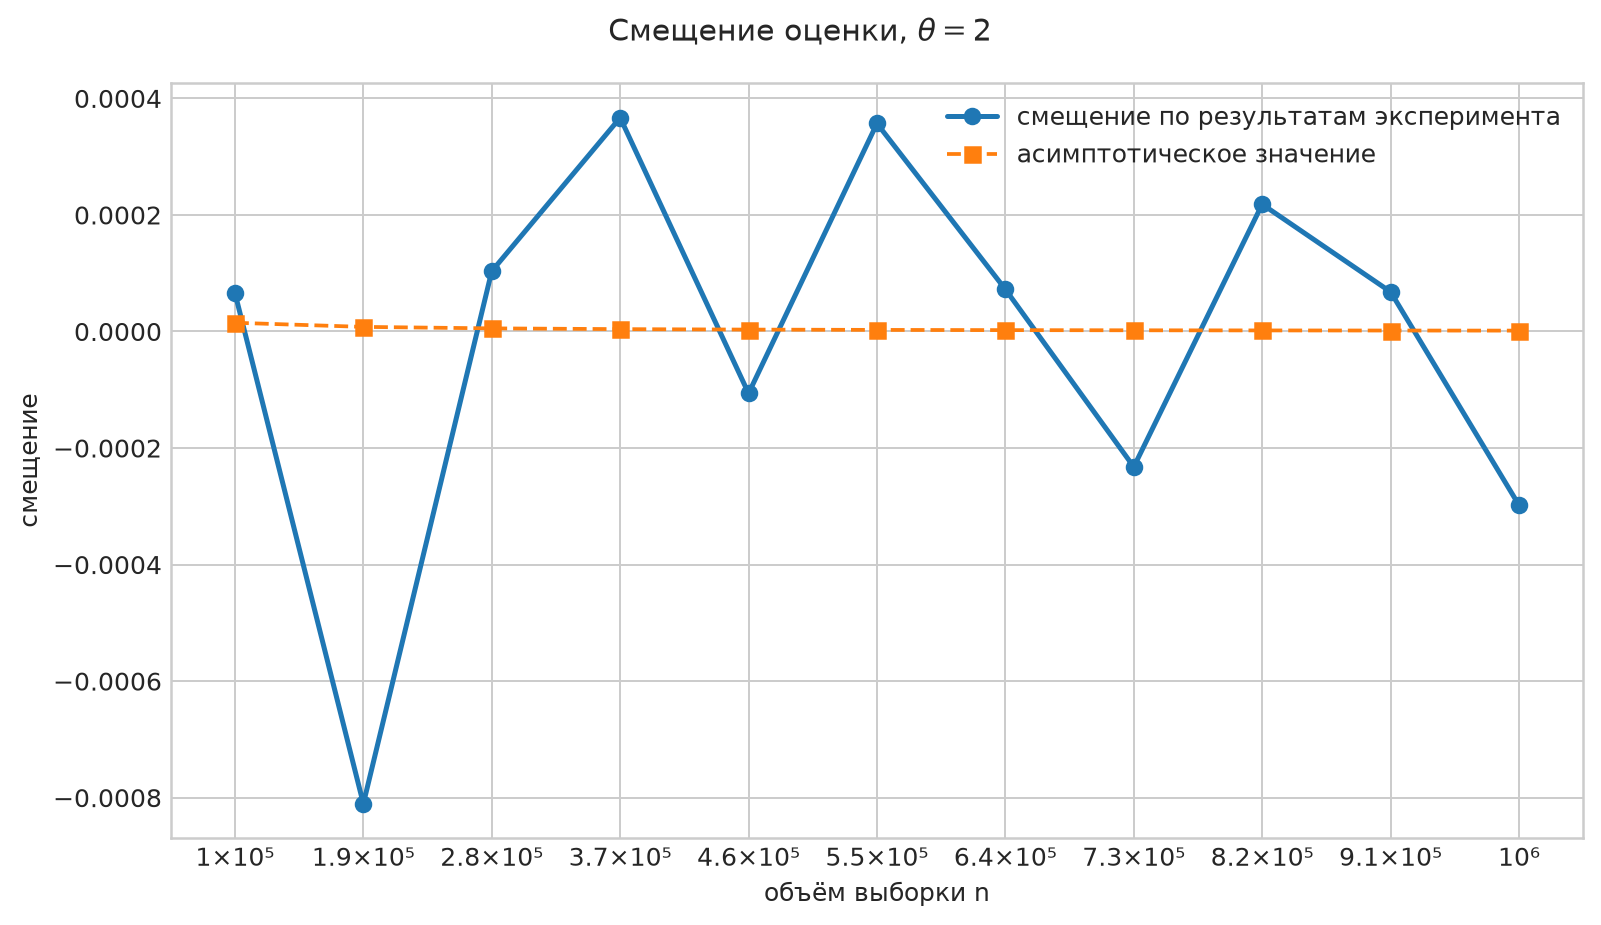

In [5]:
for sizes, experiment in zip(N, experiments):
    print(
        "Отклонение смещения в эксперименте от асимптотического:"
    )
    for n in sizes:
        theta_hats = experiment["results"][int(n)]
        mean_theta_hat = theta_hats.mean()

        experiment_bias = mean_theta_hat - THETA
        asymptotic_bias = experiment["theory"][int(n)]["bias"]
        delta = experiment_bias - asymptotic_bias

        print(f"n = {n:7d}: Δ = {delta:+.6f}")

    image = save_bias_comparison_plot(experiment, THETA)
    display(Image(filename=str(image)))

### Вывод

Асимптотическое смещение положительно и убывает как $1.5/n$. Смещение по результатам эксперимента колеблется около оранжевой линии, но с ростом размера выборки приближается ближе к асимтотическому.

## Дисперсия

В разделе смещения было введено отклонение

$$T=\overline X-\frac23$$

Для него уже получены характеристики

$$\mathbb E T=0$$

$$\operatorname{Var}(T)=\frac1{18n}$$

$$T=O(n^{-1/2})$$

$$\widehat\theta
=2+9T+27T^2+o(n^{-1})$$

$$\widehat\theta-2
=9T+27T^2+o(n^{-1})$$

Линейное слагаемое имеет порядок $n^{-1/2}$, а $27T^2$ и $o(n^{-1})$ имеют порядок не выше $n^{-1}$. Поэтому главный вклад в дисперсию даёт $9T$:

$$\operatorname{Var}(\widehat\theta)
=\operatorname{Var}(9T)+o(n^{-1})$$

$$\operatorname{Var}(9T)
=9^2\operatorname{Var}(T)
=81\cdot\frac1{18n}
=\frac9{2n}$$

Следовательно

$$\boxed{
\operatorname{Var}(\widehat\theta)
=\frac9{2n}+o(n^{-1})
}$$

Отклонение эксперементальной от асимптотической дисперсии:
n =      10: Δ = +0.567183
n =      15: Δ = +0.120080
n =      20: Δ = +0.055708
n =      25: Δ = +0.018840
n =      30: Δ = +0.006926
n =      35: Δ = -0.004557
n =      40: Δ = +0.021770
n =      45: Δ = +0.024308
n =      50: Δ = +0.032709
n =      55: Δ = +0.000972
n =      60: Δ = -0.008202
n =      65: Δ = +0.006660
n =      70: Δ = +0.014686
n =      75: Δ = -0.003201
n =      80: Δ = -0.011997
n =      85: Δ = +0.005034
n =      90: Δ = +0.015254
n =      95: Δ = -0.000574
n =     100: Δ = +0.003781


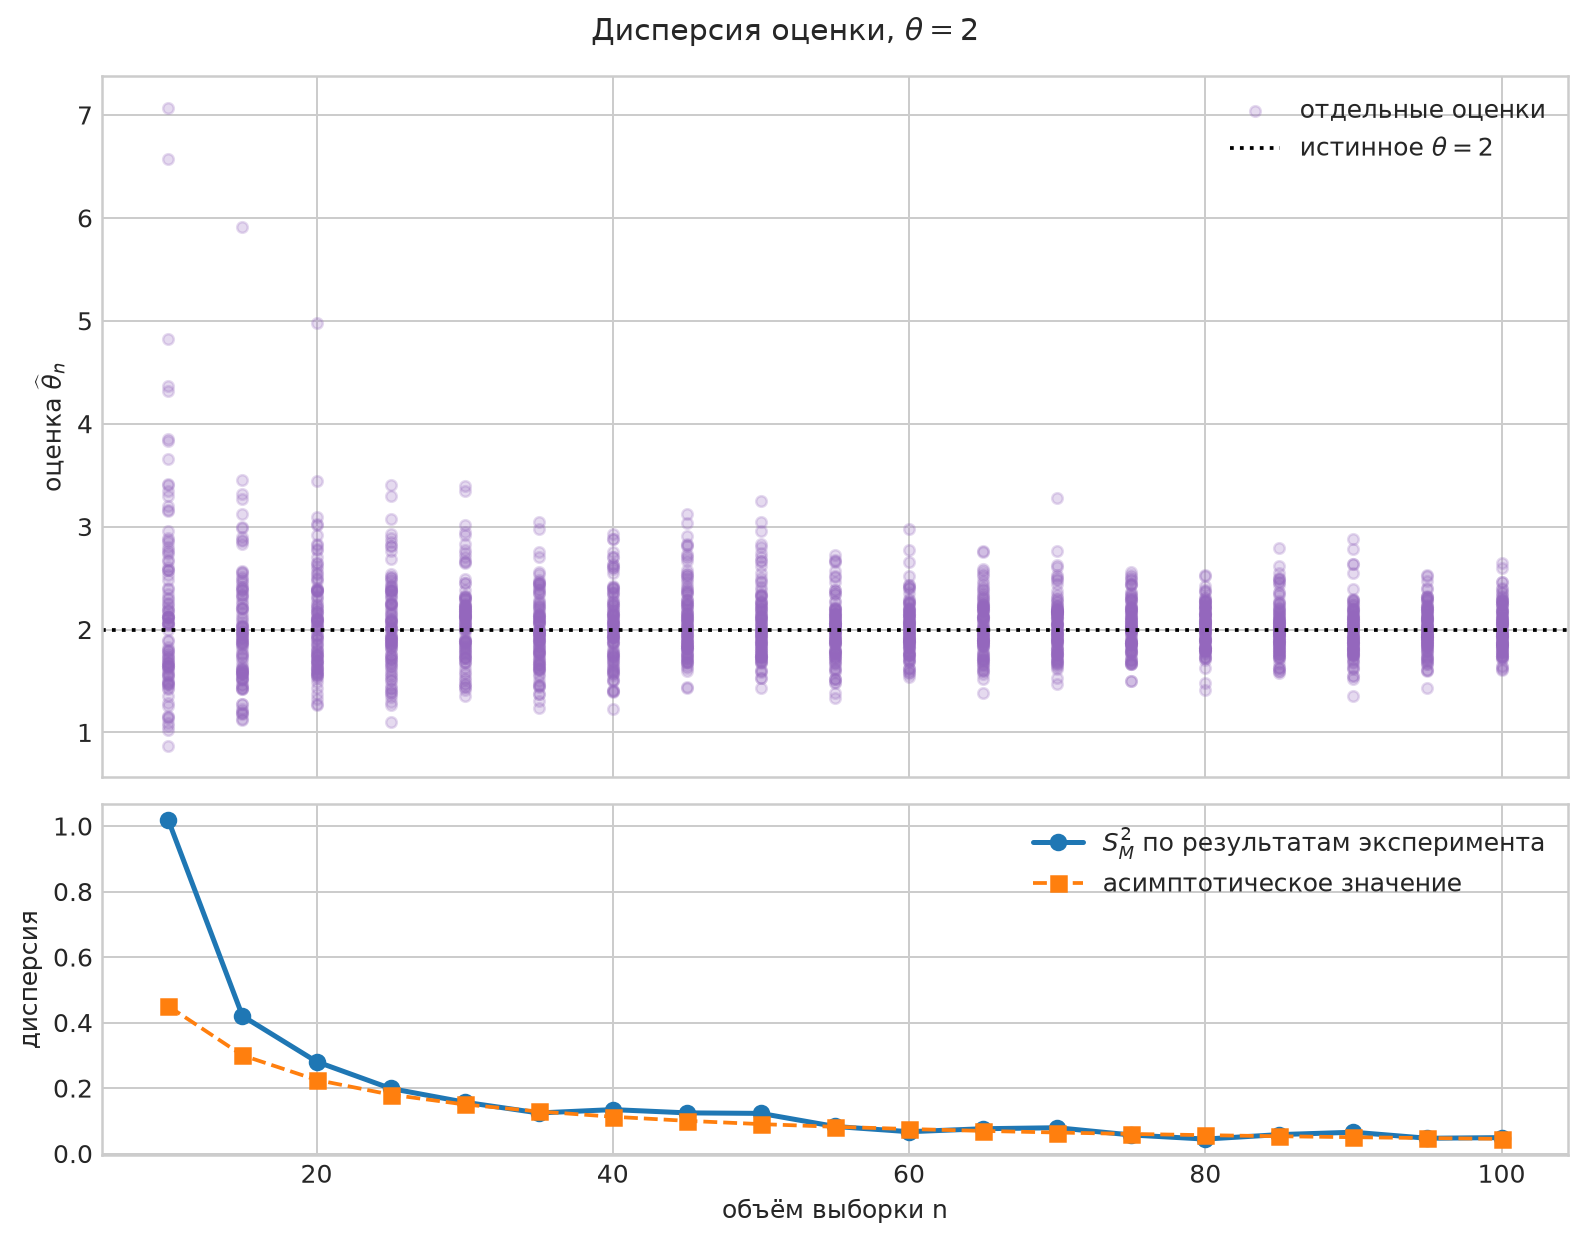

Отклонение эксперементальной от асимптотической дисперсии:
n =     100: Δ = +0.007557
n =     650: Δ = -0.000634
n =    1200: Δ = +0.000002
n =    1750: Δ = -0.000064
n =    2300: Δ = -0.000367
n =    2850: Δ = -0.000084
n =    3400: Δ = -0.000216
n =    3950: Δ = +0.000029
n =    4500: Δ = +0.000047
n =    5050: Δ = -0.000147
n =    5600: Δ = -0.000029
n =    6150: Δ = -0.000111
n =    6700: Δ = -0.000067
n =    7250: Δ = +0.000048
n =    7800: Δ = -0.000064
n =    8350: Δ = +0.000012
n =    8900: Δ = -0.000112
n =    9450: Δ = -0.000004
n =   10000: Δ = +0.000012


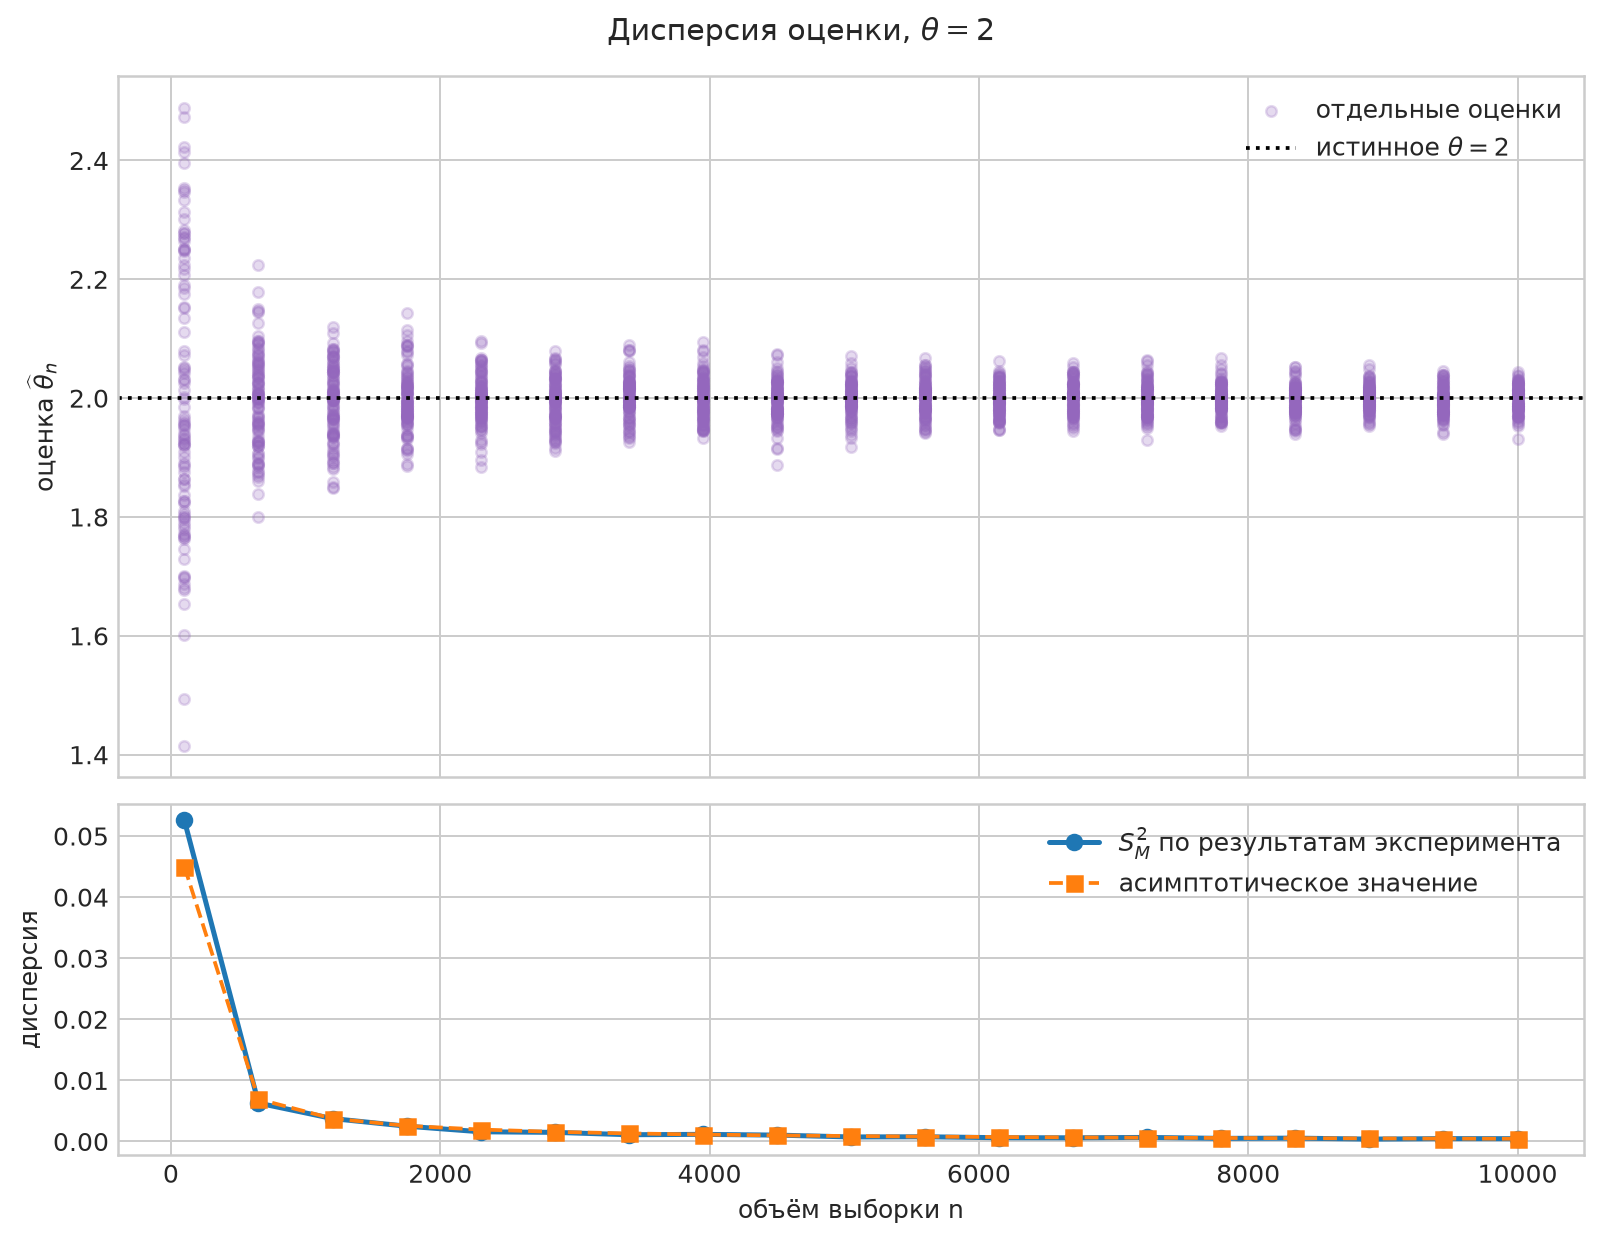

Отклонение эксперементальной от асимптотической дисперсии:
n =  100000: Δ = +0.000002
n =  190000: Δ = +0.000001
n =  280000: Δ = -0.000001
n =  370000: Δ = -0.000001
n =  460000: Δ = -0.000003
n =  550000: Δ = -0.000001
n =  640000: Δ = -0.000000
n =  730000: Δ = +0.000001
n =  820000: Δ = +0.000000
n =  910000: Δ = -0.000001
n = 1000000: Δ = -0.000000


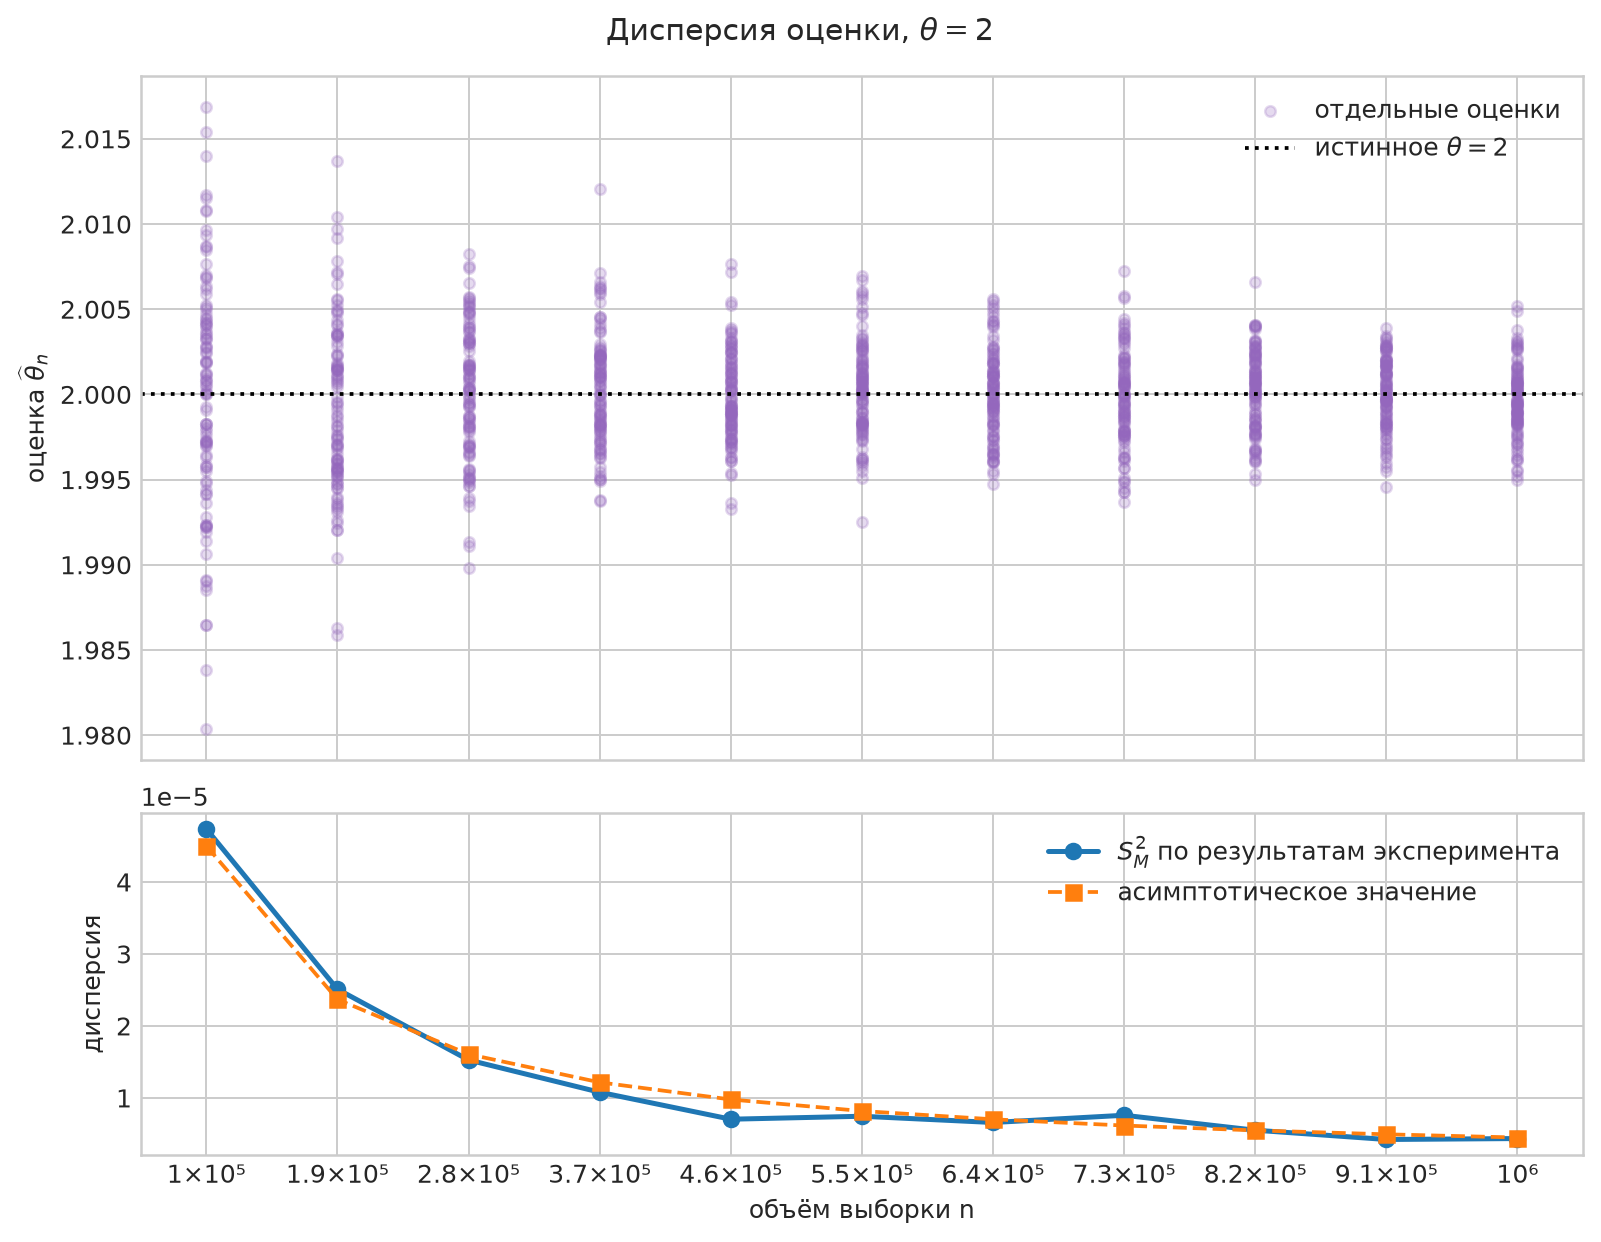

In [6]:
for sizes, experiment in zip(N, experiments):
    print(
        "Отклонение эксперементальной от асимптотической дисперсии:"
    )
    for n in sizes:
        theta_hats = experiment["results"][int(n)]
        
        experiment_variance = theta_hats.var(ddof=0)
        asymptotic_variance = experiment["theory"][int(n)]["variance"]
        delta = experiment_variance - asymptotic_variance

        print(f"n = {n:7d}: Δ = {delta:+.6f}")

    image = save_variance_comparison_plot(experiment, THETA)
    display(Image(filename=str(image)))

### Вывод

Асимптотическая дисперсия убывает как $4.5/n$, поэтому отдельные оценки всё плотнее концентрируются около нуля.

## Среднеквадратическая ошибка

$$\operatorname{MSE}(\widehat\theta)
=\operatorname{Var}(\widehat\theta)
+\operatorname{Bias}(\widehat\theta)^2$$

Подставляем полученные ранее асимптотические значения

$$\begin{aligned}
\operatorname{MSE}(\widehat\theta)
&=\left(\frac9{2n}+o(n^{-1})\right)
+\left(\frac3{2n}+o(n^{-1})\right)^2\\
&=\frac9{2n}+\frac9{4n^2}+o(n^{-1})\\
&=\frac9{2n}+o(n^{-1})
\end{aligned}$$

$$\boxed{
\operatorname{MSE}(\widehat\theta)
=\frac9{2n}+o(n^{-1})
}$$

Получили, что величина асимптотически несмещена

Отклонение MSE в эксперименте от асимптотической:
n =      10: Δ = +0.635695
n =      15: Δ = +0.120456
n =      20: Δ = +0.064891
n =      25: Δ = +0.021488
n =      30: Δ = +0.015047
n =      35: Δ = -0.004286
n =      40: Δ = +0.022509
n =      45: Δ = +0.034695
n =      50: Δ = +0.037375
n =      55: Δ = +0.001053
n =      60: Δ = -0.008054
n =      65: Δ = +0.007098
n =      70: Δ = +0.015929
n =      75: Δ = -0.001874
n =      80: Δ = -0.011435
n =      85: Δ = +0.005214
n =      90: Δ = +0.015495
n =      95: Δ = -0.000554
n =     100: Δ = +0.004207


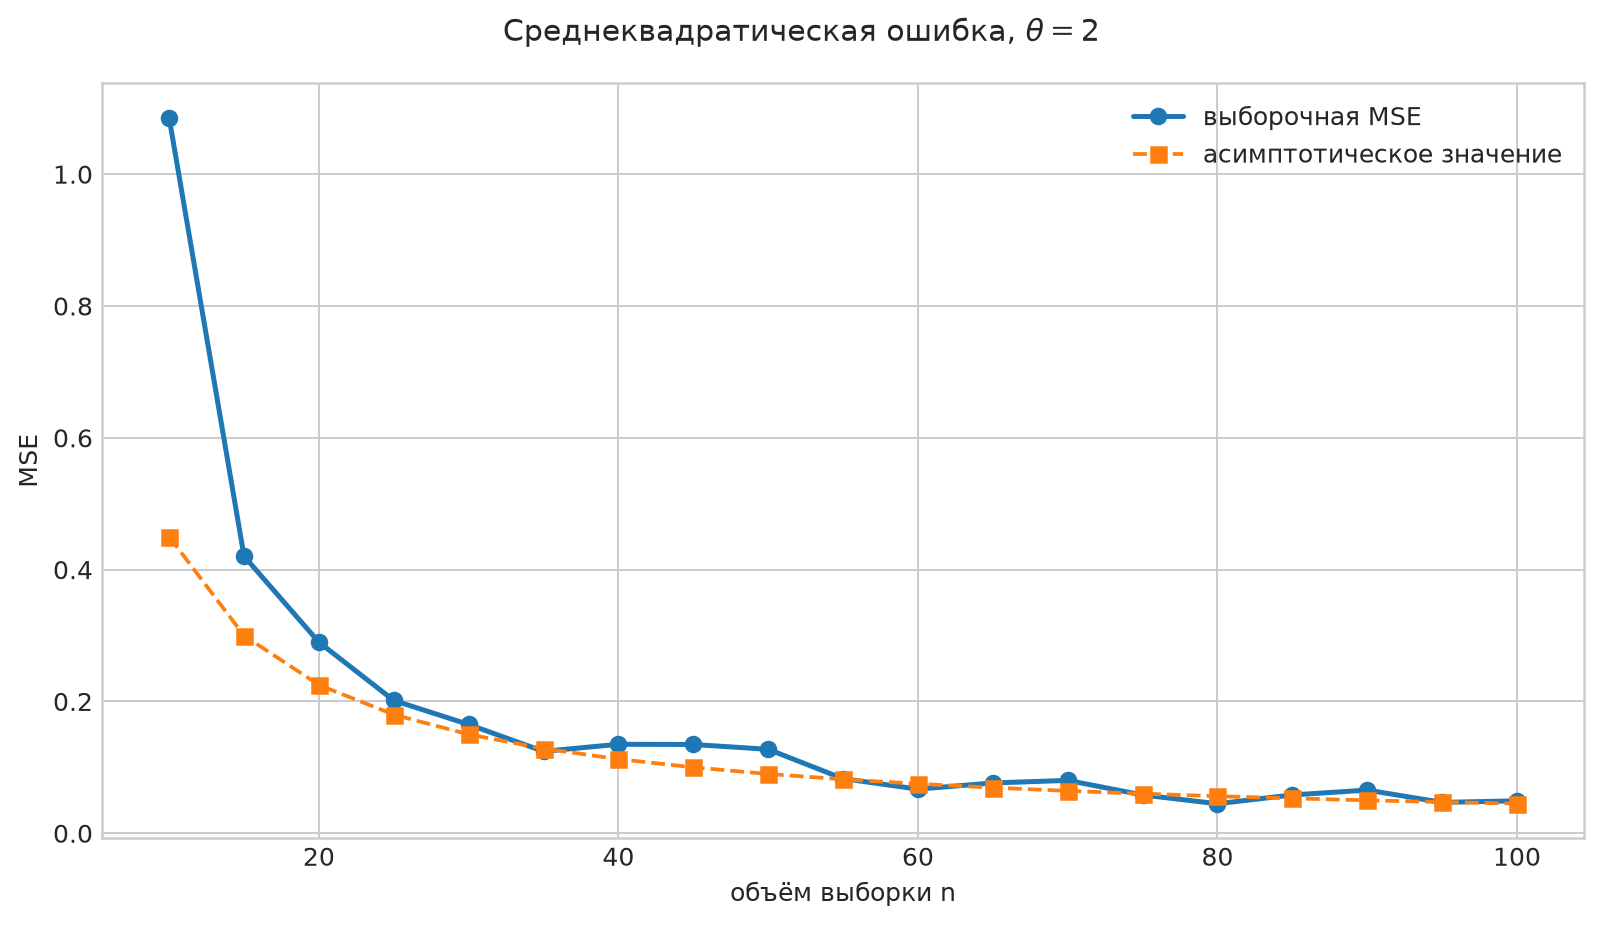

Отклонение MSE в эксперименте от асимптотической:
n =     100: Δ = +0.007592
n =     650: Δ = -0.000622
n =    1200: Δ = +0.000053
n =    1750: Δ = -0.000057
n =    2300: Δ = -0.000364
n =    2850: Δ = -0.000060
n =    3400: Δ = -0.000204
n =    3950: Δ = +0.000029
n =    4500: Δ = +0.000062
n =    5050: Δ = -0.000147
n =    5600: Δ = -0.000028
n =    6150: Δ = -0.000109
n =    6700: Δ = -0.000062
n =    7250: Δ = +0.000051
n =    7800: Δ = -0.000064
n =    8350: Δ = +0.000020
n =    8900: Δ = -0.000112
n =    9450: Δ = +0.000016
n =   10000: Δ = +0.000013


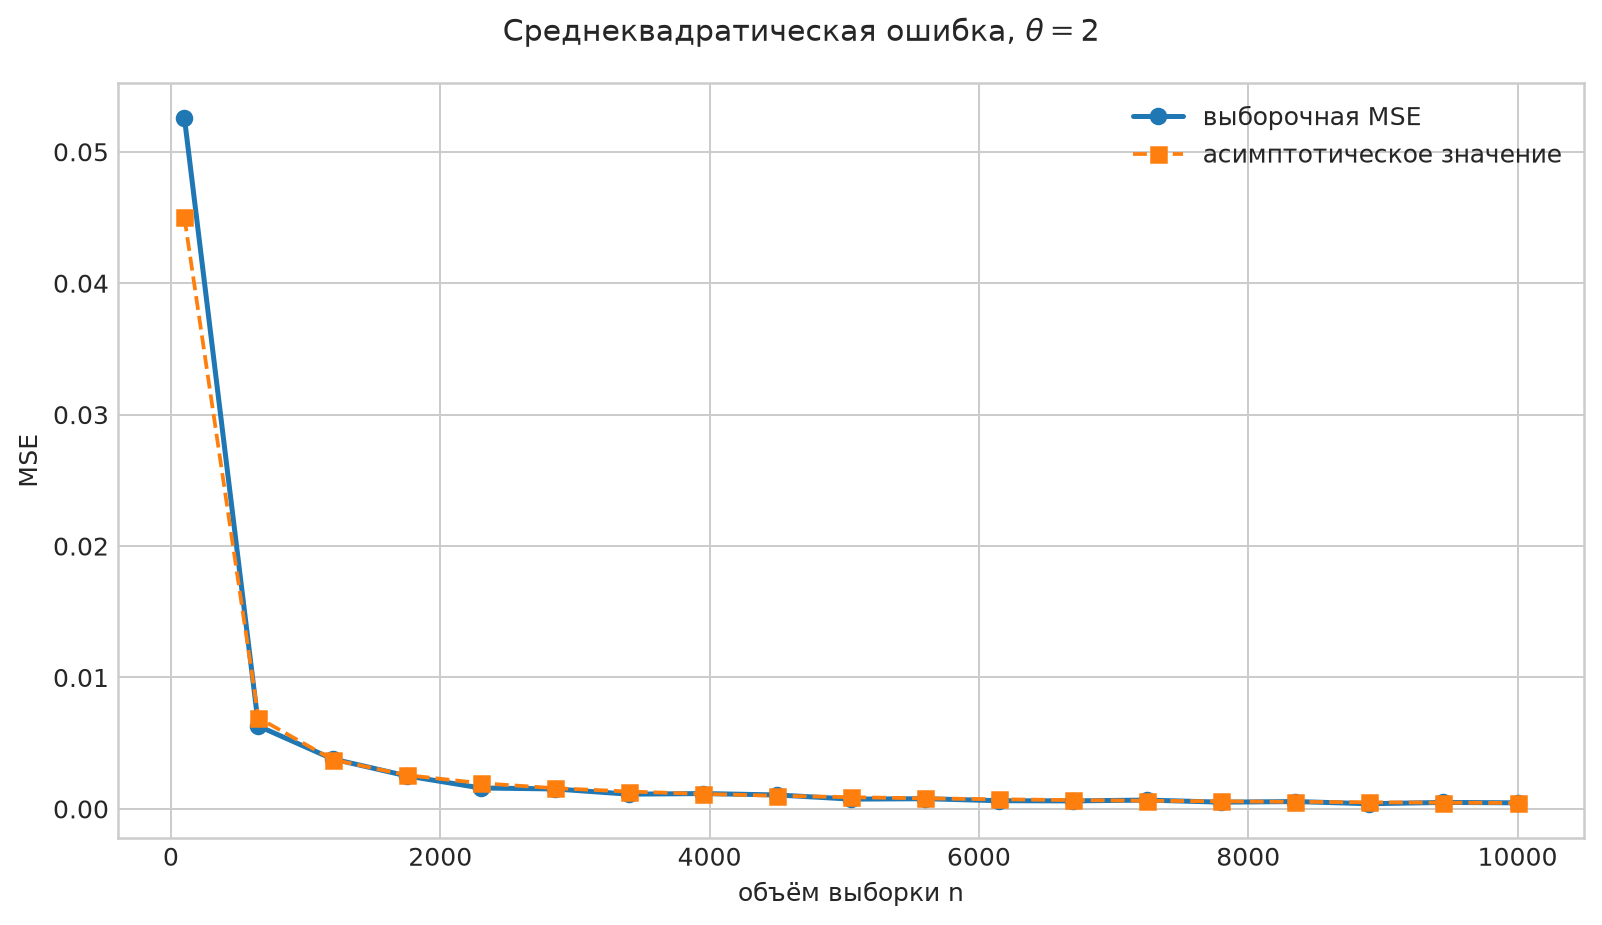

Отклонение MSE в эксперименте от асимптотической:
n =  100000: Δ = +0.000002
n =  190000: Δ = +0.000002
n =  280000: Δ = -0.000001
n =  370000: Δ = -0.000001
n =  460000: Δ = -0.000003
n =  550000: Δ = -0.000001
n =  640000: Δ = -0.000000
n =  730000: Δ = +0.000001
n =  820000: Δ = +0.000000
n =  910000: Δ = -0.000001
n = 1000000: Δ = -0.000000


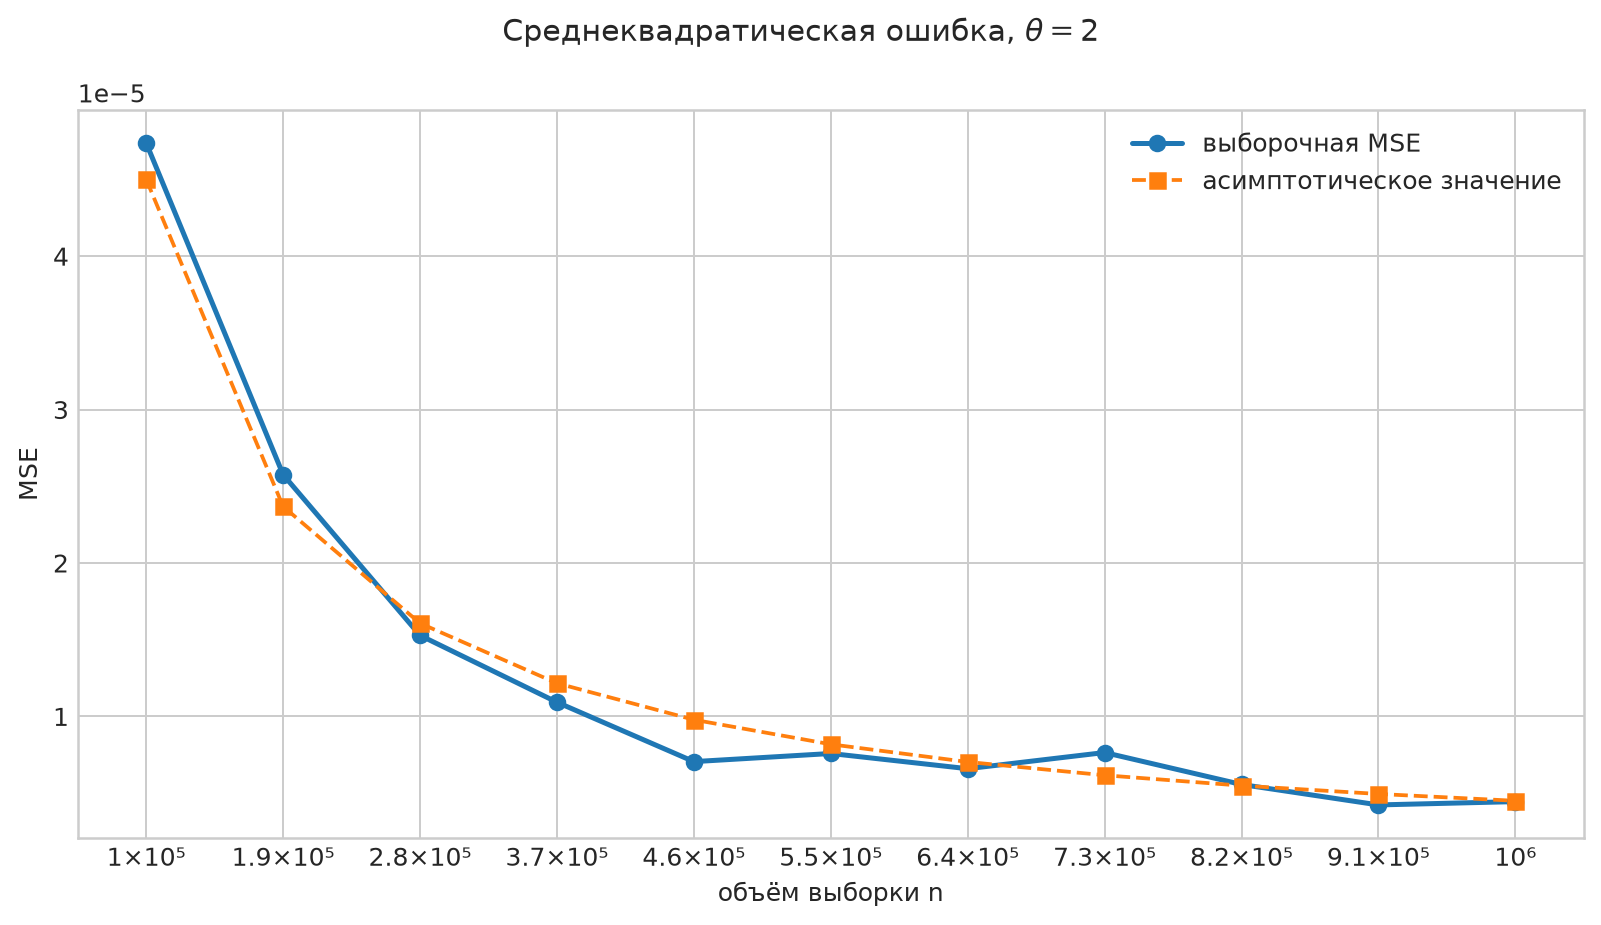

In [7]:
for sizes, experiment in zip(N, experiments):
    print(
        "Отклонение MSE в эксперименте от асимптотической:"
    )
    for n in sizes:
        theta_hats = experiment["results"][int(n)]
        errors = theta_hats - THETA
        
        experiment_mse = np.mean(errors**2)
        asymptotic_mse = experiment["theory"][int(n)]["mse"]
        delta = experiment_mse - asymptotic_mse

        print(f"n = {n:7d}: Δ = {delta:+.6f}")

    image = save_mse_comparison_plot(experiment, THETA)
    display(Image(filename=str(image)))

### Вывод

Асимптотическая MSE убывает как $4,5/n$. В целом ситуация, как у дисперсии.

## Свойства оценки

### Смещённость

Оценка смещена (в одном из предыдущих пунктов показали её приближение значения), при этом она является асимтотически несмещённой, так как стремится к нулю.

### Состоятельность

По збч выборочное среднее сходится по вероятности к математическому ожиданию

$$\overline X\xrightarrow{p}\mathbb EX
=\frac\theta{\theta+1}$$

Оценка метода моментов имеет вид

$$\widehat\theta=g(\overline X)$$

$$g(x)=\frac{x}{1-x}$$

Функция $g$ непрерывна в точке $\theta/(\theta+1)$, подставим предел в функцию

$$\widehat\theta
=g(\overline X)
\xrightarrow{p}
g(\mathbb EX)
=g\!\left(\frac\theta{\theta+1}\right)
=\frac{\frac\theta{\theta+1}}
{1-\frac\theta{\theta+1}}
=\theta$$

Следовательно

$$\boxed{
\widehat\theta\xrightarrow{p}\theta
}$$

### Асимптотическая нормальность

По цпт и используя $g(x) = \frac{x}{1-x}$, $\widehat\theta = g(\overline X)$, а $g(\mu) = \theta$

$$\sqrt n\left(\overline X-\mu\right)
\xrightarrow{d}N(0,\sigma^2)$$

$$g'(\mu)
=\frac1{(1-\mu)^2}
=(\theta+1)^2$$

По дельта-методу

$$\sqrt n\left(\widehat\theta-\theta\right)
\xrightarrow{d}
N\!\left(0,g'(\mu)\sigma^2g'(\mu)\right)$$

$$g'(\mu)^2\sigma^2
=(\theta+1)^4
\frac{\theta}{(\theta+1)^2(\theta+2)}
=\frac{\theta(\theta+1)^2}{\theta+2}$$

$$\sqrt n\left(\widehat\theta-\theta\right)
\xrightarrow{d}
N\!\left(
0,
\frac{\theta(\theta+1)^2}{\theta+2}
\right)$$

При $\theta=2$ получаем

$$\sqrt n\left(\widehat\theta-2\right)
\xrightarrow{d}N\!\left(0,\frac92\right)$$

$$\boxed{
\widehat\theta
\xrightarrow{d}
N\!\left(2,\frac9{2n}\right)}$$

### Асимптотическая эффективность

Логарифм плотности равен

$$L(\theta;x)
=\theta x^{(\theta-1)}$$

$$\ln L(\theta;x)
=\ln\theta+(\theta-1)\ln x$$

Найдём производную от этого

$$\frac{\partial \ln L(\theta;x)}{\partial\theta}
=\frac1\theta+\ln x$$

Информация Фишера:

$$I(\theta)
=\mathbb E\left(\frac1\theta+\ln X\right)^2$$

Нашли первые два момента и подставили: 

$$\begin{aligned}
I(\theta)
&=\mathbb E\left(
\frac1{\theta^2}
+\frac2\theta\ln X
+(\ln X)^2
\right)\\
&=\frac1{\theta^2}
+\frac2\theta\mathbb E\ln X
+\mathbb E(\ln X)^2\\
&=\frac1{\theta^2}
-\frac2{\theta^2}
+\frac2{\theta^2}\\
&=\frac1{\theta^2}
\end{aligned}$$

Для независимой выборки объёма $n$ информация Фишера складывается

$$I_n(\theta)=nI(\theta)=\frac n{\theta^2}$$

По неравенству Рао-Крамера

$$\operatorname{Var}(\widehat\theta)
\geq\frac1{I_n(\theta)}
=\frac{\theta^2}{n}$$

Но у нас оценка смещённая, но не асимптотически, поэтому для проверки асимптотической эффективности сравниваем её асимптотическую дисперсию с асимптотической границей Рао—Крамера $\theta^2/n$.

Для оценки метода моментов (если расписать в общем случае)

$$\operatorname{Var}(\widehat\theta)
\sim
\frac{\theta(\theta+1)^2}{(\theta+2)n}$$

Найдём разность между этой дисперсией и границей Рао—Крамера

$$\begin{aligned}
\frac{\theta(\theta+1)^2}{(\theta+2)n}
-\frac{\theta^2}{n}
&=\frac{\theta(\theta+1)^2-\theta^2(\theta+2)}{(\theta+2)n}
=\frac{\theta}{(\theta+2)n}
= \frac{2}{(2+2)n}
= \frac{1}{2n}
>0
\end{aligned}$$

Асимптотическая дисперсия оценки метода моментов строго больше нижней границы Рао—Крамера. Следовательно, оценка не является асимптотически эффективной.

## Превышение заданного порога

Для всех наших объёмов выборки построим графики, как распределены конкретные запуски, а также подсчитаем кол-во экспериментов, при которых значение находится вне допустимого интервала (превышает нашу предполагаемую ошибку).

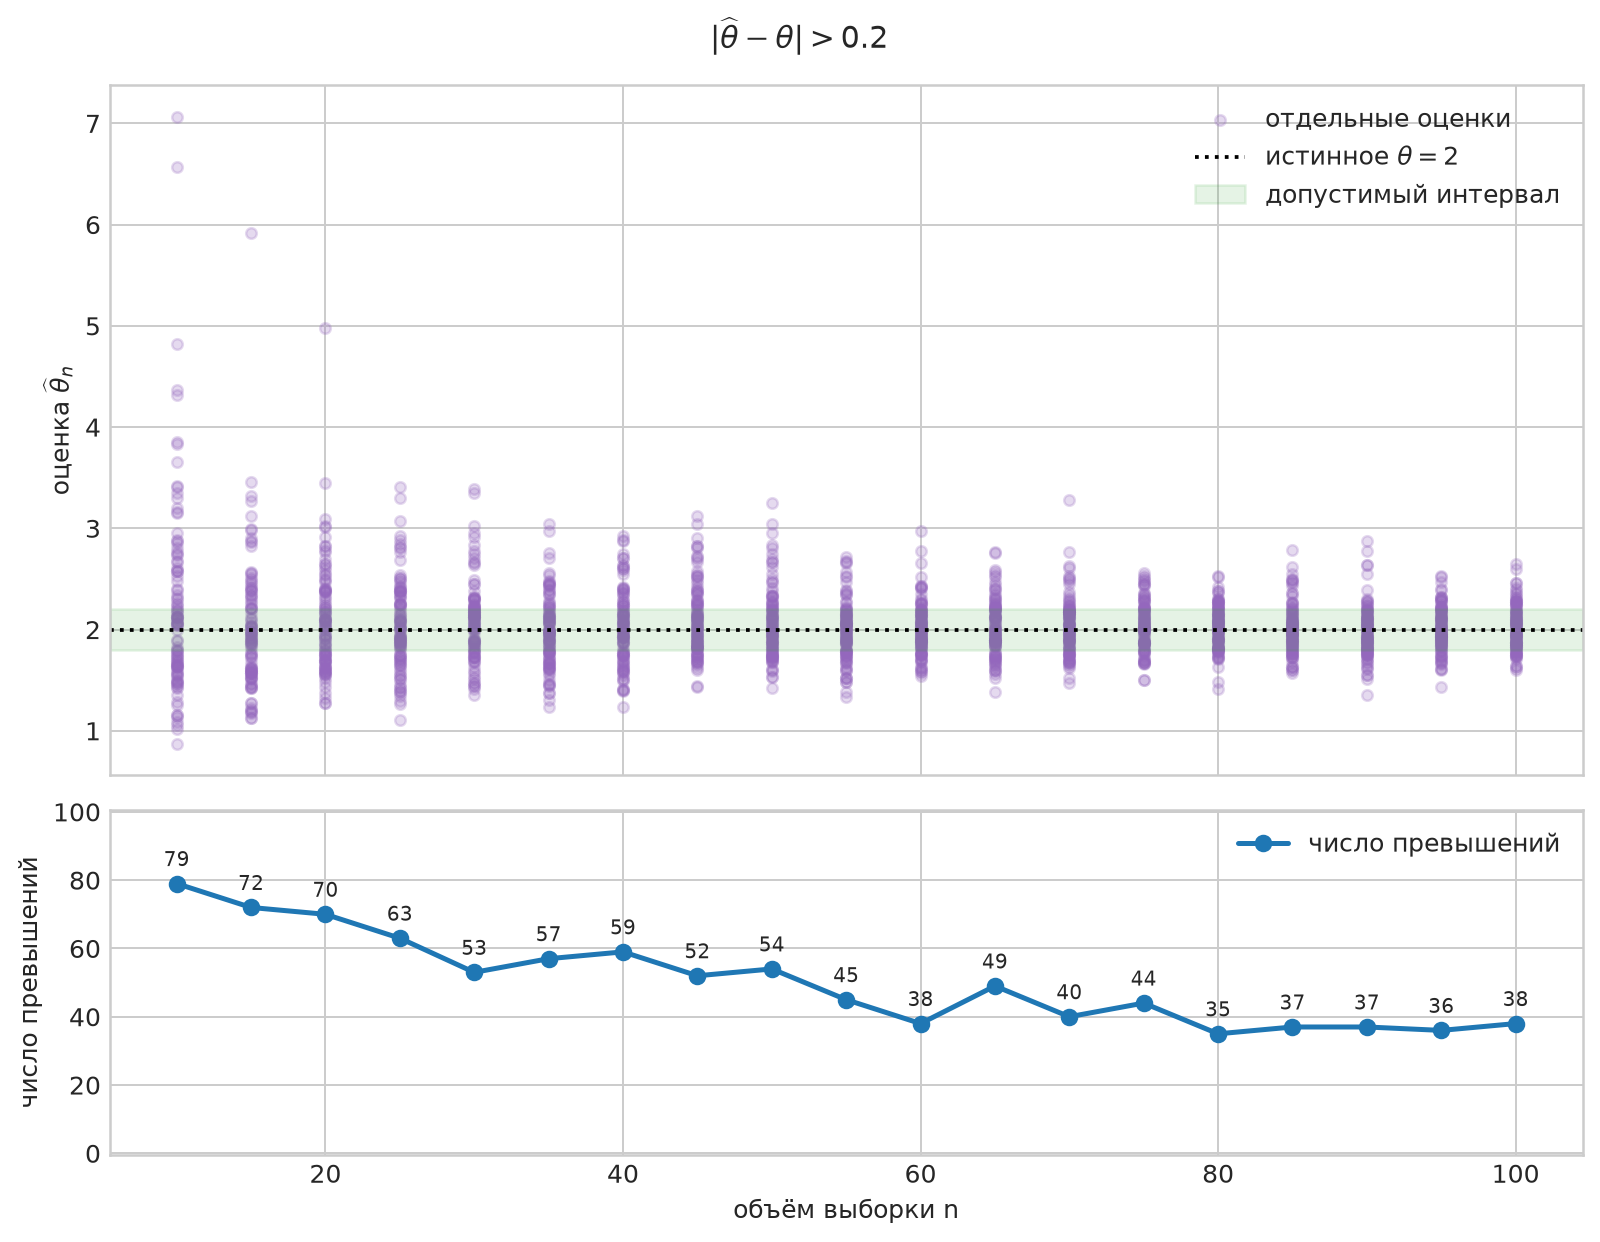

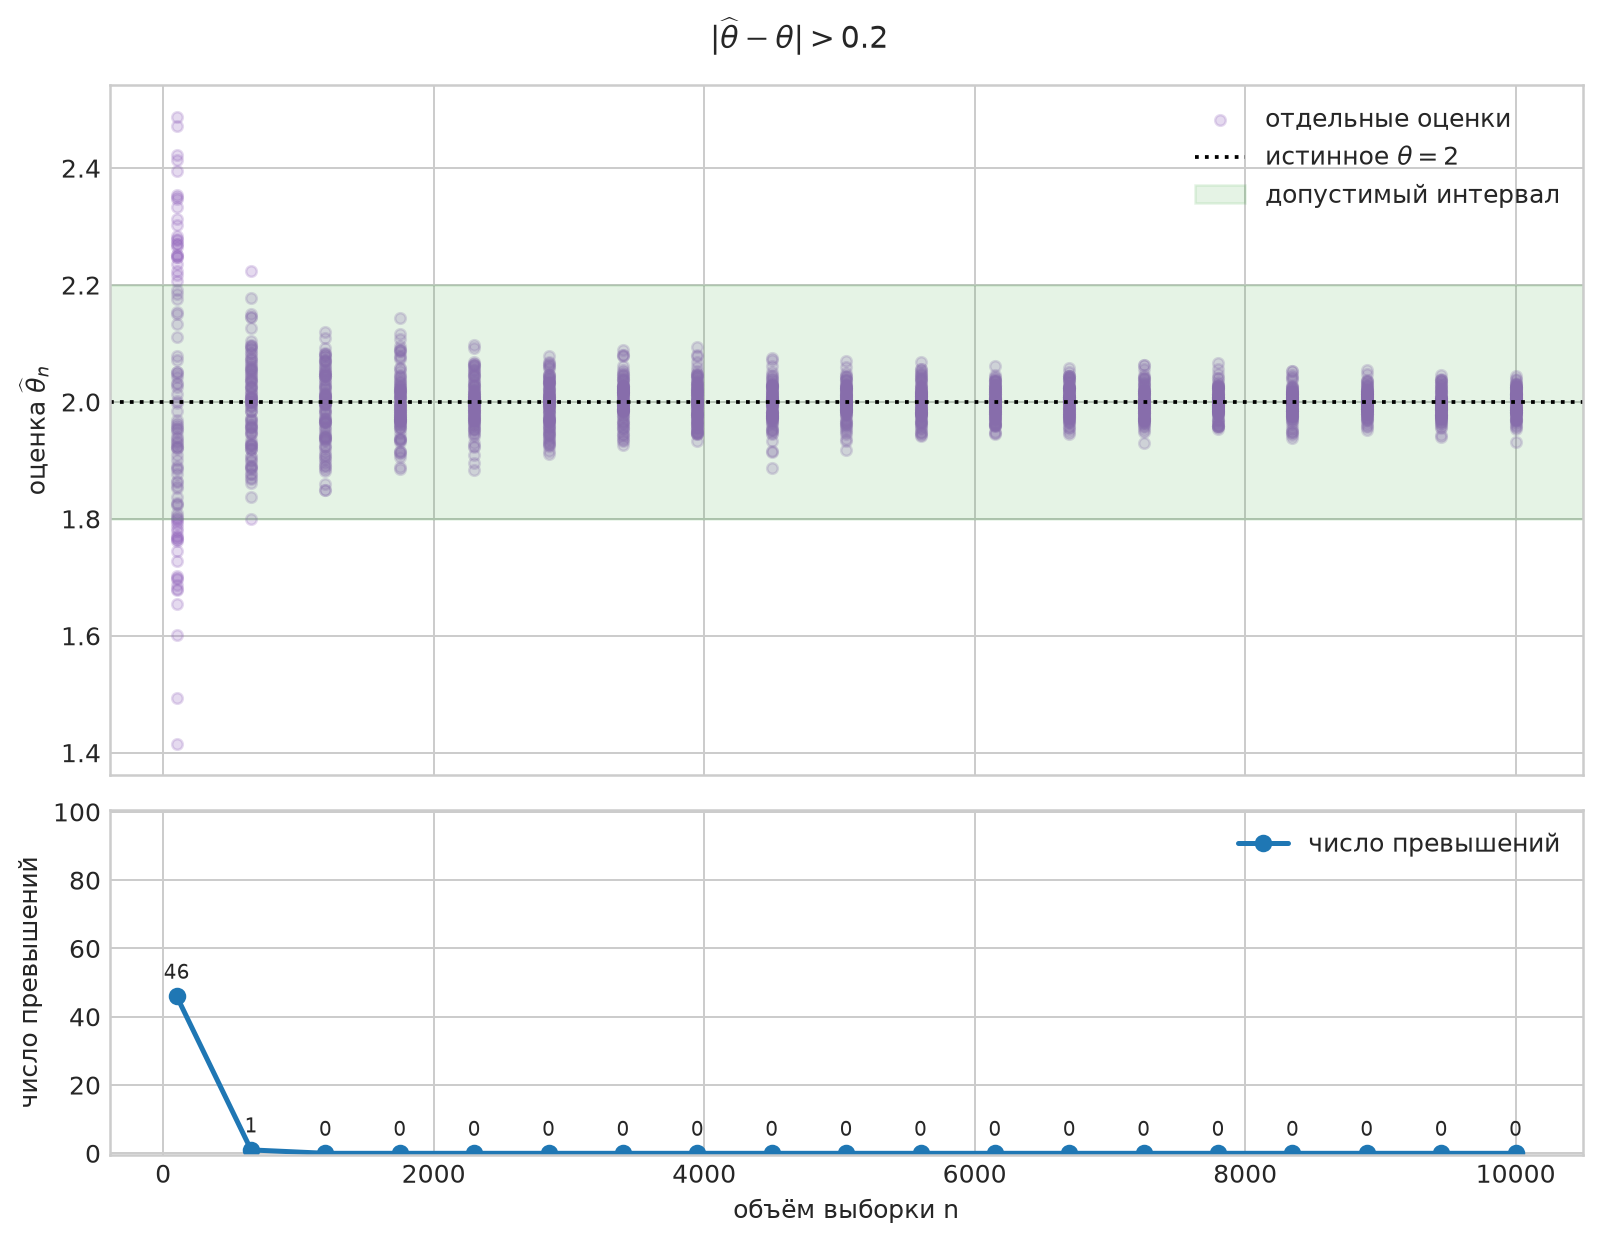

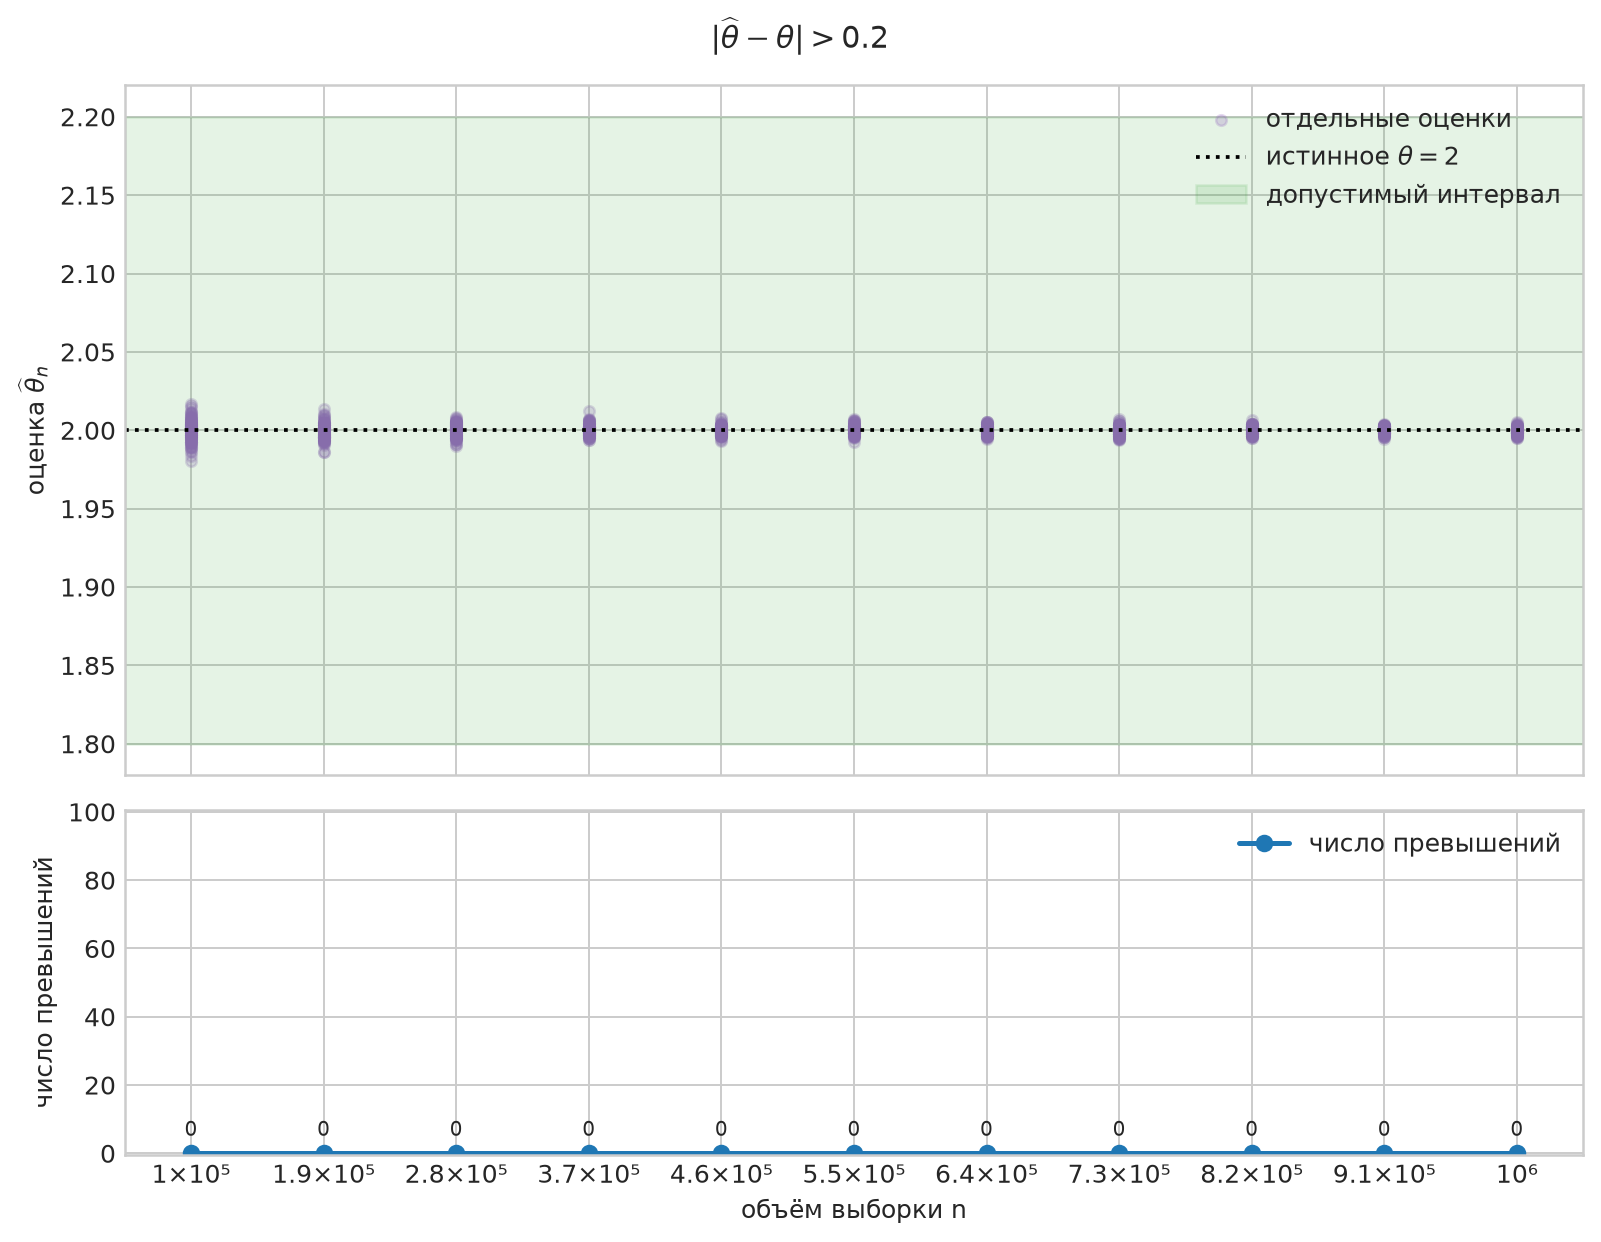

In [8]:
for experiment in experiments:
    image = save_threshold_exceedance_plot(
        experiment, THETA, threshold
    )
    display(Image(filename=str(image)))

### Вывод

На каждой из трёх шкал число выходов за интервал $[1.8,2.2]$ уменьшается при росте $n$. И на больших объёмах становится равным нулю.

## Выводы

$$\widehat\theta=\frac{\overline X}{1-\overline X}$$

$$\mathbb E\widehat\theta
=2+\frac3{2n}+o(n^{-1})$$

$$\operatorname{Bias}(\widehat\theta)
=\frac3{2n}+o(n^{-1})$$

$$\operatorname{Var}(\widehat\theta)
=\frac9{2n}+o(n^{-1})$$

$$\operatorname{MSE}(\widehat\theta)
=\frac9{2n}+o(n^{-1})$$

$$\widehat\theta\xrightarrow{p}\theta$$

$$\widehat\theta
\xrightarrow{}
N\!\left(2,\frac9{2n}\right)$$

Оценка смещена, но асимптотически несмещённая. Также не эффективная.